# Milestone 3: YOLOv8 Detection

This notebook documents the 13-identity detection dataset, three YOLOv8 fine-tuning runs, validation-based model selection, held-out test results, and a predicted-box gallery. It also demonstrates inference on a test image and on separately supplied images, including a 3 × 3 grid.

## 1. Dataset check

In [1]:
from pathlib import Path
import hashlib
import json
import subprocess
import sys
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image as DisplayImage, display

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Start Jupyter from the repository root or notebooks directory")
sys.path.insert(0, str(ROOT))
from src.m3_protocol import ARTIFACTS, DATASET, RUNS, SPLIT_COUNTS, validate_dataset
from src.m3_training import SWEEP

DEVICE = "0"
def run_module(module, *arguments):
    """Run one experiment stage and keep its saved outputs."""
    command = [sys.executable, "-m", module, *map(str, arguments)]
    with subprocess.Popen(command, cwd=ROOT, stdout=subprocess.PIPE,
                          stderr=subprocess.STDOUT, text=True, bufsize=1) as process:
        for line in process.stdout:
            print(line, end="")
        if process.wait():
            raise subprocess.CalledProcessError(process.returncode, command)

names = validate_dataset()
display(pd.DataFrame({"split": list(SPLIT_COUNTS),
                      "images": list(SPLIT_COUNTS.values())}))
print(f"Validated {len(names)} identity classes:", list(names.values()))

,split,images
0,train,156
1,val,39
2,test,39


Validated 13 identity classes: ['3', '7', '797', '1212', '2336', '2619', '2970', '4422', '4428', '5695', '7007', '8335', '10002']


## 2. Train three pretrained YOLOv8s models

The baseline uses learning rate 0.001 and image size 640. The other runs change either learning rate or image size. The same train/validation split and fixed training settings are used in all three runs.

In [2]:
run_module("src.m3_training", "train", "--run", "lr001_img640", "--device", DEVICE)

Completed run preserved: lr001_img640


In [3]:
run_module("src.m3_training", "train", "--run", "lr0005_img640", "--device", DEVICE)

New https://pypi.org/project/ultralytics/8.4.174 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.253 🚀 Python-3.10.16 torch-2.5.1 CUDA:0 (Tesla P100-PCIE-12GB, 12194MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/zhang.jiaso/ondemand/data/sys/dashboard/batch_connect/sys/jupyterlab-ml-courses/ie7615-project1/runs/m3/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.1, hsv_v=0.1, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s

In [4]:
run_module("src.m3_training", "train", "--run", "lr001_img512", "--device", DEVICE)

New https://pypi.org/project/ultralytics/8.4.174 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.253 🚀 Python-3.10.16 torch-2.5.1 CUDA:0 (Tesla P100-PCIE-12GB, 12194MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/zhang.jiaso/ondemand/data/sys/dashboard/batch_connect/sys/jupyterlab-ml-courses/ie7615-project1/runs/m3/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.1, hsv_v=0.1, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.

## 3. Compare validation performance and select the checkpoint

Selection uses validation mAP@0.5:0.95, with validation mAP@0.5 as the tie-breaker.

In [5]:
selection_path = ARTIFACTS / "selection.json"
if not selection_path.is_file():
    run_module("src.m3_training", "select")
selection = json.loads(selection_path.read_text(encoding="utf-8"))
checkpoint = ARTIFACTS / "best.pt"
# Confirm that the displayed selection uses the saved checkpoint.
assert hashlib.sha256(checkpoint.read_bytes()).hexdigest() == selection["checkpoint_sha256"]
comparison = pd.read_csv(ARTIFACTS / "validation_comparison.csv")
display(comparison[["run", "lr0", "imgsz", "val_precision", "val_recall",
                    "val_map50", "val_map50_95"]])
print("Selected by validation:", selection["selected_run"])

Selected lr0005_img640 by validation mAP50-95


,run,lr0,imgsz,val_precision,val_recall,val_map50,val_map50_95
0,lr001_img640,0.0010,640,0.853945,0.861134,0.928124,0.927316
1,lr0005_img640,0.0005,640,0.853929,0.891341,0.953825,0.952853
2,lr001_img512,0.0010,512,0.868821,0.849982,0.930450,0.929864


Selected by validation: lr0005_img640


## 4. Training and validation loss curves

The three rows compare training and validation box, class, and DFL losses across epochs for the sweep runs.

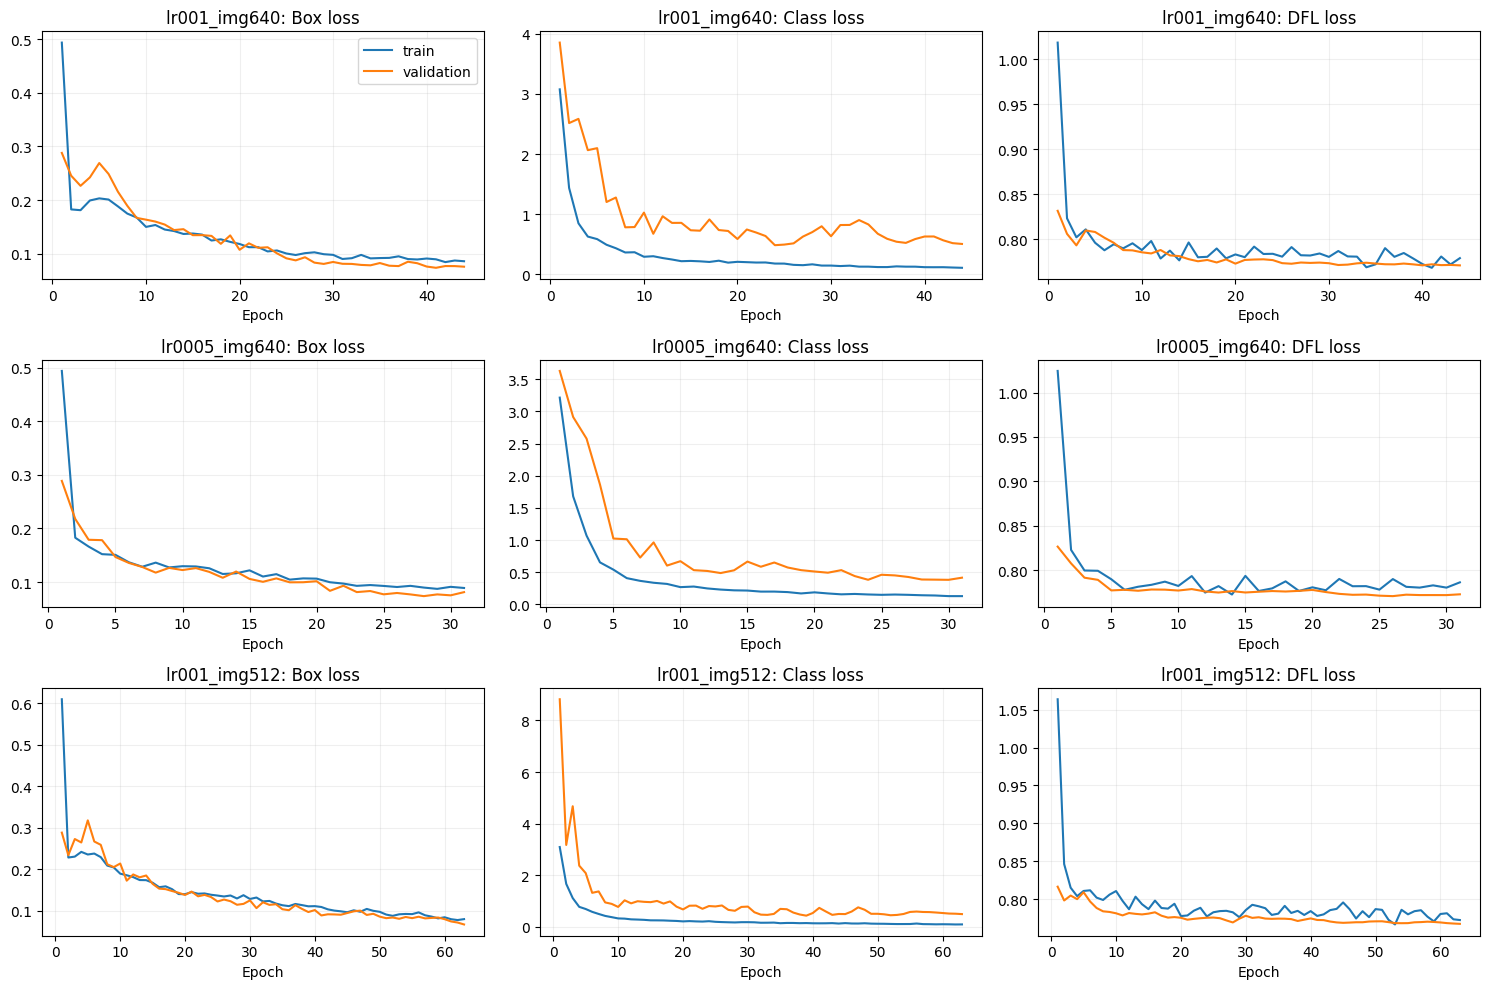

In [6]:
loss_pairs = [
    ("train/box_loss", "val/box_loss", "Box loss"),
    ("train/cls_loss", "val/cls_loss", "Class loss"),
    ("train/dfl_loss", "val/dfl_loss", "DFL loss"),
]
fig, axes = plt.subplots(len(SWEEP), len(loss_pairs), figsize=(15, 10))
for row, run_name in enumerate(SWEEP):
    history = pd.read_csv(RUNS / run_name / "results.csv")
    history.columns = history.columns.str.strip()
    for col, (train_key, val_key, title) in enumerate(loss_pairs):
        ax = axes[row, col]
        ax.plot(history["epoch"], history[train_key], label="train")
        ax.plot(history["epoch"], history[val_key], label="validation")
        ax.set_title(f"{run_name}: {title}")
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.2)
        if row == 0 and col == 0:
            ax.legend()
plt.tight_layout()
display(fig)
plt.close(fig)

## 5. Held-out test metrics

Ultralytics reports overall and per-class precision, recall, mAP@0.5, and mAP@0.5:0.95. Mean matched-box IoU uses class-correct one-to-one matches at IoU ≥ 0.5 and prediction confidence 0.25. Localization is measured against M2 portrait-region labels.

In [7]:
test_path = ARTIFACTS / "test_metrics.json"
gallery_path = ROOT / "m3_gallery"
# Reuse saved results so the held-out test split is evaluated only once.
if not test_path.is_file():
    run_module("src.m3_evaluation", "evaluate", "--device", DEVICE)
elif not gallery_path.exists():
    run_module("src.m3_evaluation", "gallery", "--device", DEVICE)
elif len(list(gallery_path.glob("*.jpg"))) < 10:
    raise ValueError("The prediction gallery needs at least ten images")
test = json.loads(test_path.read_text(encoding="utf-8"))
display(pd.DataFrame([{
    "images": test["images"], "precision": test["precision"],
    "recall": test["recall"], "mAP@0.5": test["map50"],
    "mAP@0.5:0.95": test["map50_95"],
    "mean matched IoU": test["mean_matched_iou"],
    **test["matched_counts"],
}]))
display(pd.read_csv(ARTIFACTS / "per_class_metrics.csv"))

Ultralytics 8.3.253 🚀 Python-3.10.16 torch-2.5.1 CUDA:0 (Tesla P100-PCIE-12GB, 12194MiB)
Model summary (fused): 72 layers, 11,130,615 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 31.5±12.6 MB/s, size: 67.6 KB)

val: Scanning /home/zhang.jiaso/ondemand/data/sys/dashboard/batch_connect/sys/jupyterlab-ml-courses/ie7615-project1/data/m2_detection/labels/test... 39 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 39/39 1.1Kit/s 0.0s
val: New cache created: /home/zhang.jiaso/ondemand/data/sys/dashboard/batch_connect/sys/jupyterlab-ml-courses/ie7615-project1/data/m2_detection/labels/test.cache

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 33% ━━━━──────── 1/3 1.2it/s 0.3s<1.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 67% ━━━━━━━━──── 2/3 2.0it/s 0.5s<0.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━

,images,precision,recall,mAP@0.5,mAP@0.5:0.95,mean matched IoU,tp,fp,fn
0,39,0.697414,0.730512,0.809109,0.809109,0.984384,125,69,50


,identity,precision,recall,map50,map50_95,mean_matched_iou,matched_boxes
0,3,0.582783,0.642857,0.677051,0.677051,0.985568,7
1,7,0.620423,0.857143,0.944091,0.944091,0.983637,12
2,797,0.801855,0.538462,0.707829,0.707829,0.982016,7
3,1212,0.729481,0.578369,0.786758,0.786758,0.980027,8
4,2336,1.000000,0.509663,0.941130,0.941130,0.986385,5
5,2619,0.912601,0.857143,0.900142,0.900142,0.986121,13
6,2970,0.324332,0.642857,0.597025,0.597025,0.984538,10
7,4422,0.754050,0.615385,0.693150,0.693150,0.986200,7
8,4428,0.743224,0.928571,0.907406,0.907406,0.984384,11
9,5695,0.921771,0.907405,0.940337,0.940337,0.983235,12


## 6. Predicted-box gallery

The table summarizes matched, missed, and extra predictions for each held-out test image. Ten gallery images show predicted boxes with identity IDs and confidence scores. Captions for these examples appear in `m3_gallery/gallery.md`.

,image,ground_truth,predictions,tp,fp,fn,mean_matched_iou
0,test_0000.jpg,2,3,1,2,1,0.992693
1,test_0001.jpg,3,4,2,2,1,0.987301
2,test_0002.jpg,4,4,2,2,2,0.990927
3,test_0003.jpg,5,5,2,3,3,0.984904
4,test_0004.jpg,9,10,8,2,1,0.985349
5,test_0005.jpg,2,1,1,0,1,0.974833
6,test_0006.jpg,3,3,2,1,1,0.990226
7,test_0007.jpg,4,4,4,0,0,0.985770
8,test_0008.jpg,5,6,4,2,1,0.988817
9,test_0009.jpg,9,11,6,5,3,0.981291


01_test_0020.jpg


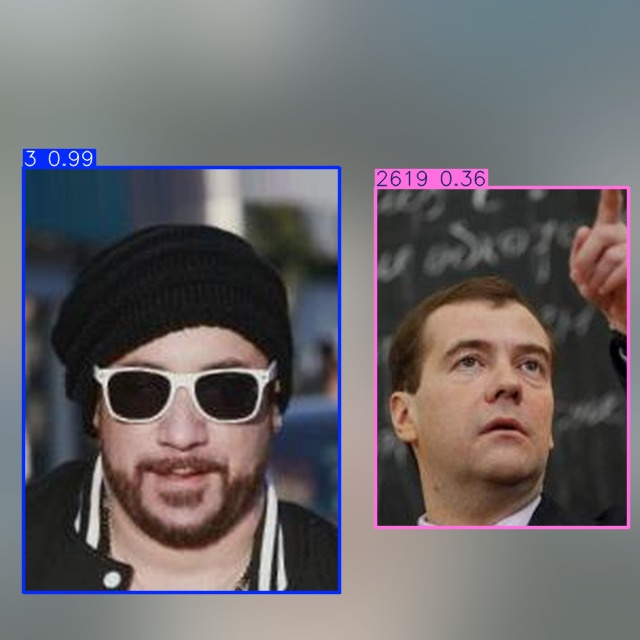

02_test_0030.jpg


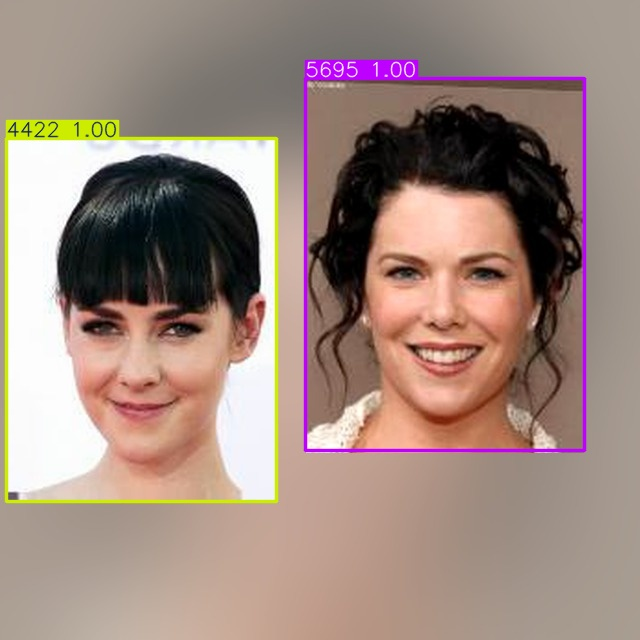

03_test_0007.jpg


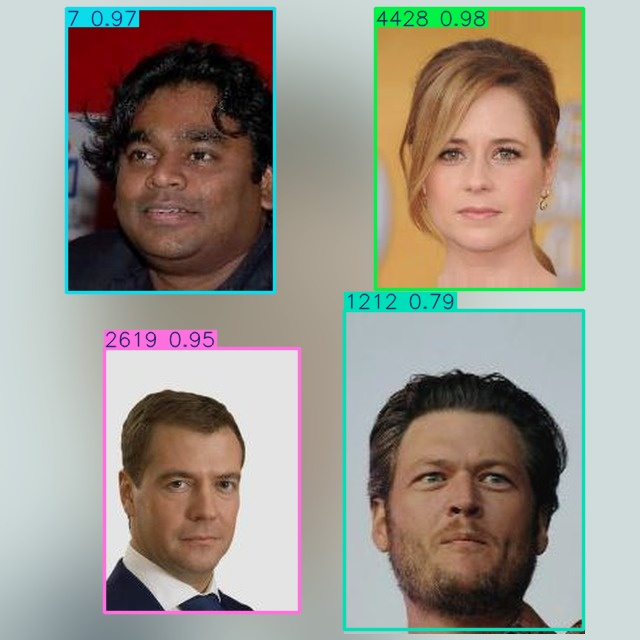

04_test_0025.jpg


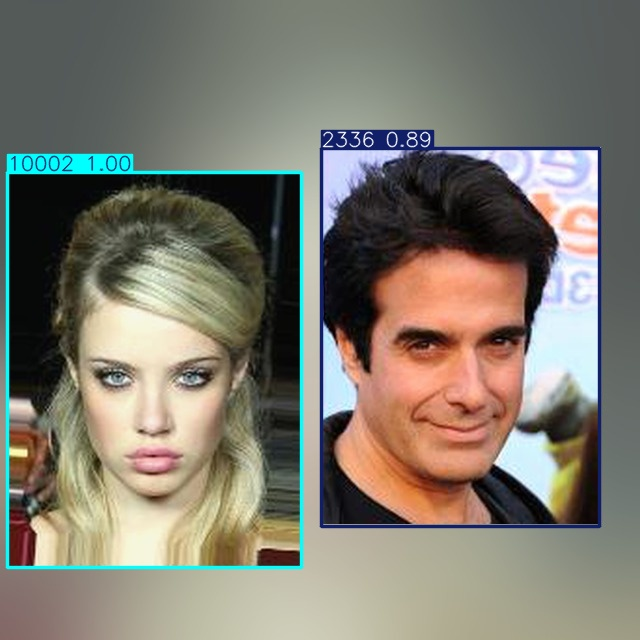

05_test_0021.jpg


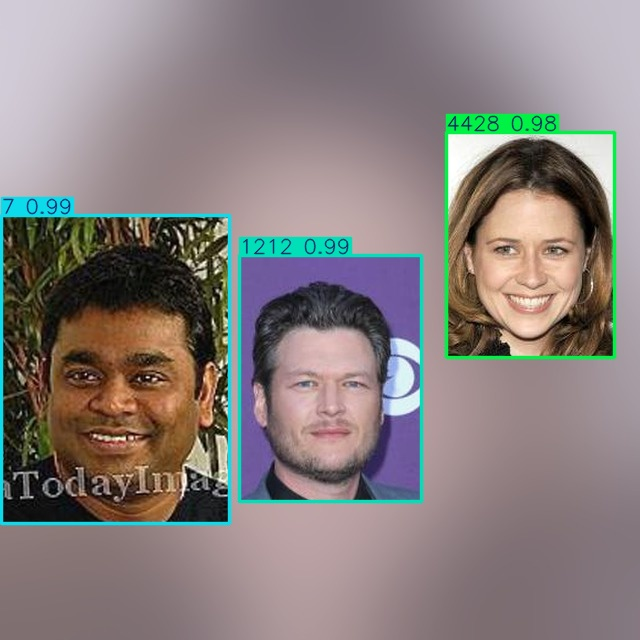

06_test_0009.jpg


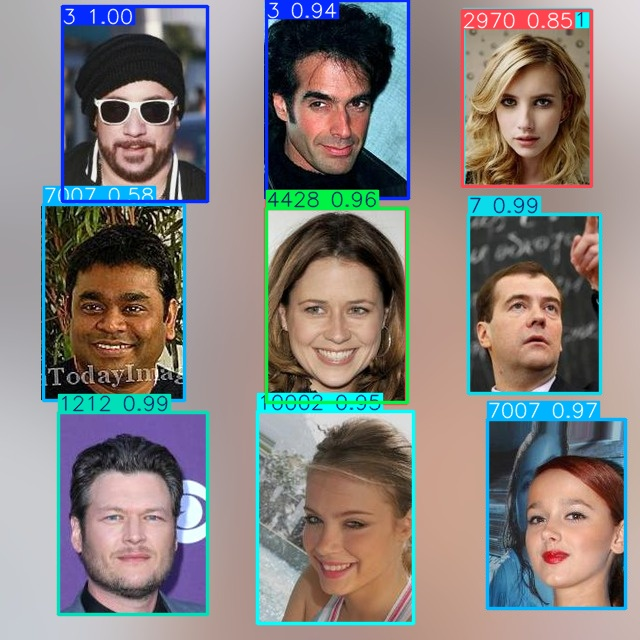

07_test_0024.jpg


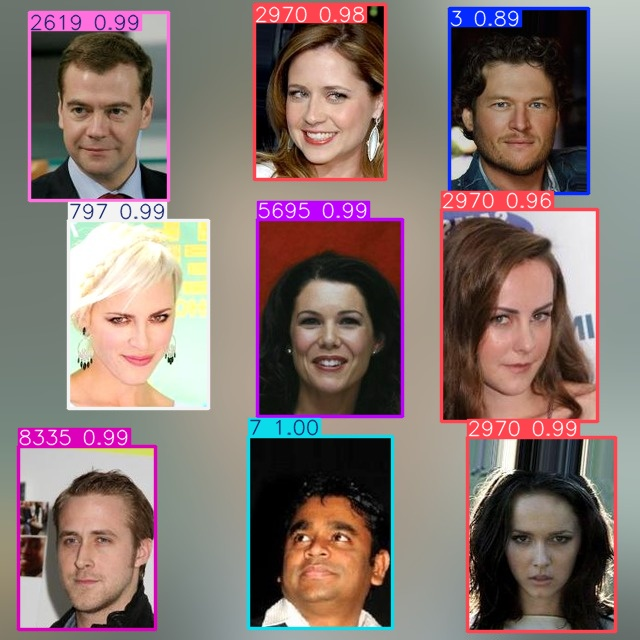

08_test_0019.jpg


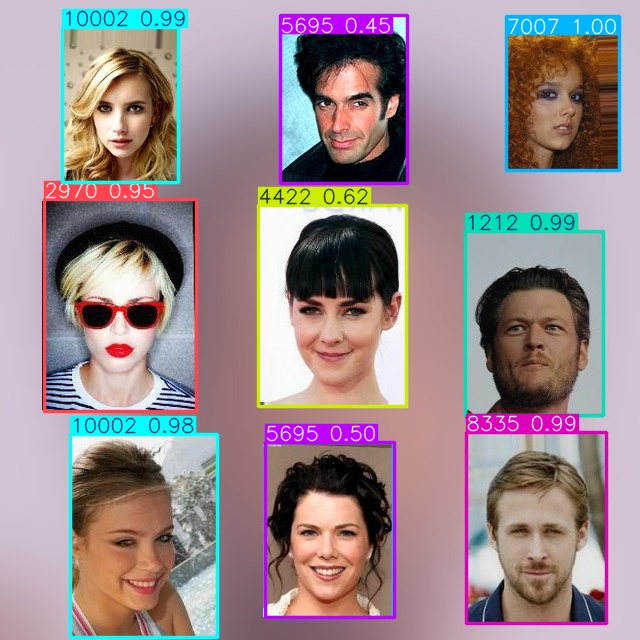

09_test_0003.jpg


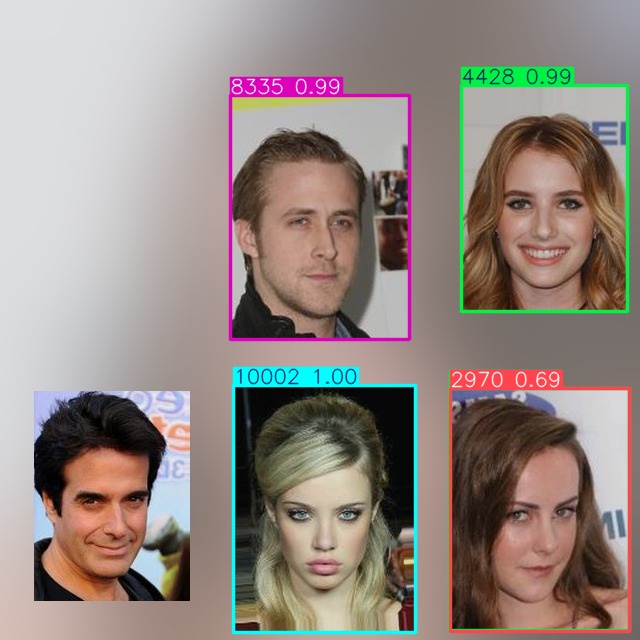

10_test_0029.jpg


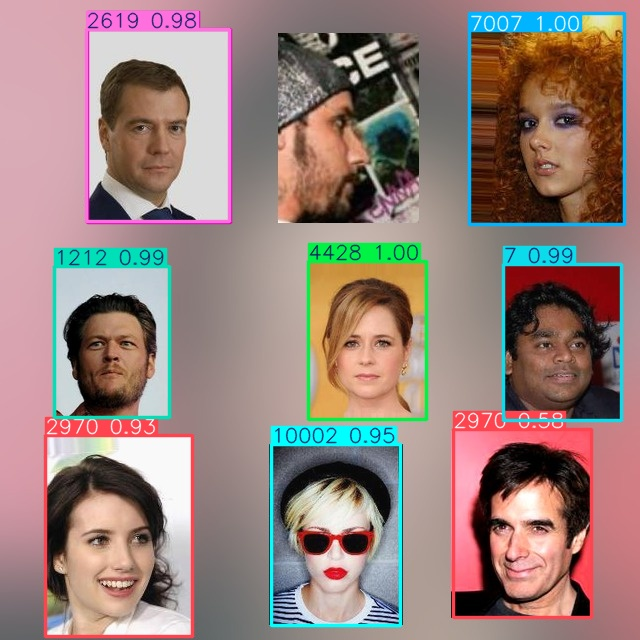

Captions: /home/zhang.jiaso/ondemand/data/sys/dashboard/batch_connect/sys/jupyterlab-ml-courses/ie7615-project1/m3_gallery/gallery.md


In [8]:
review = pd.DataFrame(json.loads(
    (ARTIFACTS / "per_image_review.json").read_text(encoding="utf-8")
))
display(review[["image", "ground_truth", "predictions", "tp", "fp", "fn",
                "mean_matched_iou"]])
for image_path in sorted(gallery_path.glob("*.jpg")):
    print(image_path.name)
    display(DisplayImage(filename=str(image_path), width=480))
if (gallery_path / "gallery.md").is_file():
    print("Captions:", gallery_path / "gallery.md")

## 7. Test-image inference demo

The demo loads the validation-selected detector and runs inference on one held-out test image. It displays the annotated result and reports each predicted identity ID, confidence score, and bounding box.

Annotated image: /home/zhang.jiaso/ondemand/data/sys/dashboard/batch_connect/sys/jupyterlab-ml-courses/ie7615-project1/m3_demo_prediction.jpg
ID 4428: confidence=1.000, box=[47.4, 4.3, 169.1, 171.4]
ID 4422: confidence=0.999, box=[16.4, 401.7, 185.2, 629.0]
ID 7007: confidence=0.997, box=[225.7, 2.2, 353.6, 175.4]
ID 7: confidence=0.995, box=[22.8, 197.0, 149.8, 368.3]
ID 5695: confidence=0.990, box=[486.3, 191.8, 629.0, 389.0]
ID 2619: confidence=0.983, box=[236.0, 191.0, 384.0, 391.9]
ID 3: confidence=0.871, box=[254.5, 400.9, 416.6, 622.3]
ID 10002: confidence=0.804, box=[489.6, 17.3, 608.8, 177.9]
ID 1212: confidence=0.718, box=[444.7, 404.6, 598.2, 611.3]
ID 8335: confidence=0.549, box=[445.2, 404.9, 599.5, 612.5]



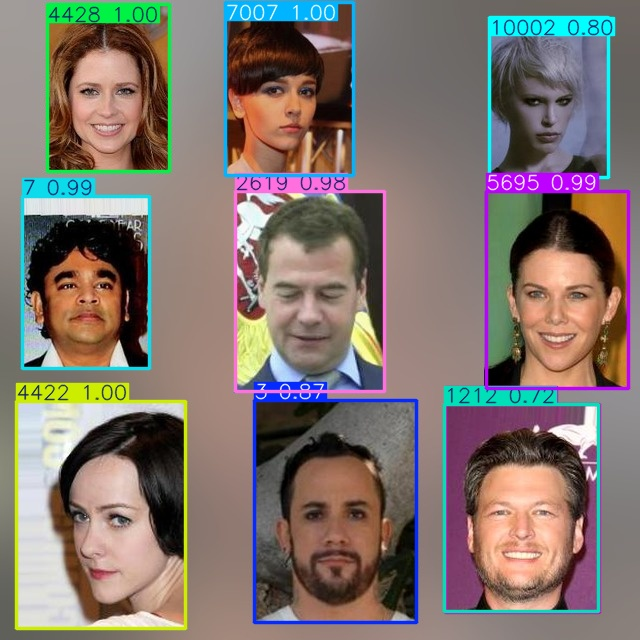

In [9]:
from pathlib import Path
import subprocess
import sys
from IPython.display import Image as DisplayImage, display

ROOT = Path.cwd().resolve()
if not (ROOT / "demo_m3.py").is_file():
    ROOT = ROOT.parent
if not (ROOT / "demo_m3.py").is_file():
    raise RuntimeError("Start Jupyter from the repository root or notebooks directory")
DEVICE = "0"
demo_image = ROOT / "data/m2_detection/images/test/test_0004.jpg"
demo_output = ROOT / "m3_demo_prediction.jpg"
demo = subprocess.run(
    [sys.executable, str(ROOT / "demo_m3.py"), str(demo_image),
     "--output", str(demo_output), "--device", DEVICE],
    cwd=ROOT, capture_output=True, text=True,
)
print(demo.stdout)
if demo.stderr:
    print(demo.stderr)
demo.check_returncode()
display(DisplayImage(filename=str(demo_output), width=640))

## 8. Additional sample inference

This section applies the selected detector to separately supplied images, including multi-person grids. It displays predicted identity IDs, confidence scores, and boxes. These predictions are qualitative checks separate from the held-out test metrics.

Input: ta_week3_grid_01.jpg
Prediction: data/m3_external_predictions/ta_week3_grid_01_jpg_prediction.jpg
ID 5695: confidence=0.999, box=[24.8, 446.1, 204.6, 625.5]
ID 797: confidence=0.998, box=[12.3, 232.4, 192.2, 415.2]
ID 7007: confidence=0.997, box=[438.9, 440.0, 622.1, 623.9]
ID 2970: confidence=0.995, box=[434.4, 5.7, 614.8, 186.6]
ID 10002: confidence=0.994, box=[447.7, 226.8, 634.3, 416.3]
ID 4422: confidence=0.992, box=[220.2, 435.1, 402.8, 620.1]
ID 2336: confidence=0.992, box=[24.6, 11.5, 208.3, 196.4]
ID 1212: confidence=0.905, box=[223.4, 237.2, 394.5, 407.0]
ID 3: confidence=0.318, box=[228.8, 16.7, 398.4, 189.7]


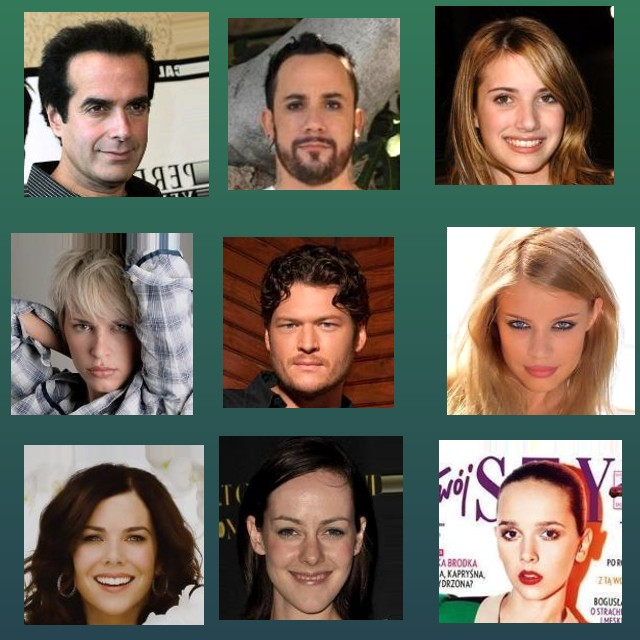

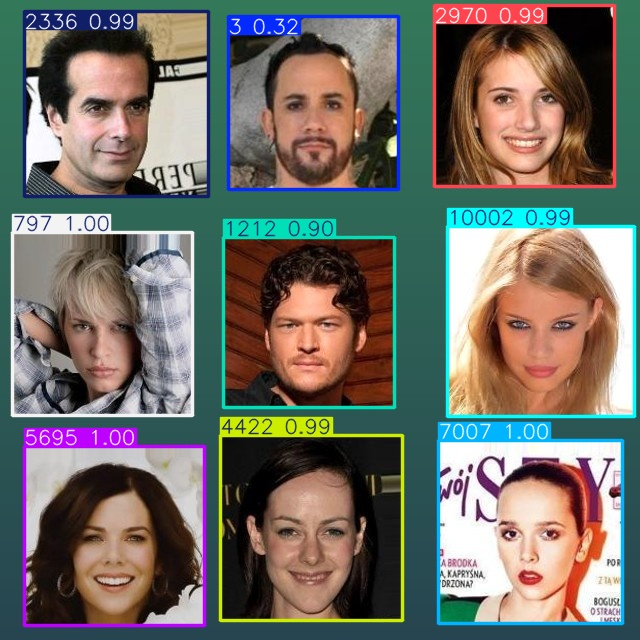

Processed 1 additional sample image(s).


In [2]:
from pathlib import Path
import subprocess
import sys
from IPython.display import Image as DisplayImage, display

ROOT = Path.cwd().resolve()
if not (ROOT / "demo_m3.py").is_file():
    ROOT = ROOT.parent
if not (ROOT / "demo_m3.py").is_file():
    raise RuntimeError("Start Jupyter from the repository root or notebooks directory")

DEVICE = "0"
sample_dir = ROOT / "data/m3_external_samples"
output_dir = ROOT / "data/m3_external_predictions"
samples = sorted(path for path in sample_dir.rglob("*")
                 if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png"})

if not samples:
    print("No additional sample images found; this section is skipped.")
else:
    # A grid is one input file and can produce multiple identity boxes.
    for sample in samples:
        relative = sample.relative_to(sample_dir)
        suffix = relative.suffix.lower().lstrip(".")
        prediction = output_dir / relative.parent / f"{relative.stem}_{suffix}_prediction.jpg"
        run = subprocess.run(
            [sys.executable, str(ROOT / "demo_m3.py"), str(sample),
             "--output", str(prediction), "--device", DEVICE],
            cwd=ROOT, capture_output=True, text=True,
        )
        if run.returncode:
            raise RuntimeError(f"Detection failed for {relative}:\n{run.stdout}\n{run.stderr}")
        prediction_text = prediction.with_suffix(".txt")
        prediction_text.write_text(run.stdout, encoding="utf-8")
        print(f"Input: {relative}")
        print(f"Prediction: {prediction.relative_to(ROOT).as_posix()}")
        for line in run.stdout.splitlines():
            if not line.startswith("Annotated image:"):
                print(line)
        display(DisplayImage(filename=str(sample), width=320))
        display(DisplayImage(filename=str(prediction), width=640))

    print(f"Processed {len(samples)} additional sample image(s).")
